# Arctic and subarctic marine mammal call classification
### An unsupervised, supervised, and transformer based bioacoustics demonstration

**Author:** Erzsebet (Eli) Frey, ecologist (MSc Ecology, University of Belgrade)

**Context:** a second one day methods demonstration built in support of a PhD
application (Data Science / Bioinformatics for Marine and Arctic Biodiversity,
AWI / MarDATA), this time focused on the sequence and transformer based
skills the posting lists (eDNA, sequence data, transformer based models),
applied here to marine mammal bioacoustic sequences rather than genetic ones,
since both are sequence classification problems at heart. Portfolio style
proof of concept, not a peer reviewed analysis, see the Limitations section.

**Data:** a 225 clip subset of the [Watkins Marine Mammal Sound
Database](https://cis.whoi.edu/science/B/whalesounds/index.cfm), Woods Hole
Oceanographic Institution (Watkins, Sayigh, Daher and colleagues), a
freely accessible archive of about 2000 marine mammal recordings across 60
plus species built from decades of field recordings. The official WHOI site
was down for maintenance while this project was built, so the clips were
pulled directly from the public [Internet Archive
mirror](https://archive.org/details/watkins-marine-mammal-sound-database-full-cuts)
of the full database, 25 real recordings each for nine species, chosen
directly from that server without downloading the full 6 gigabyte archive.
See `LICENSE_DATA.md` for full attribution and citation details.

**Species used**, six genuinely Arctic or Subarctic and three widely
distributed comparison species:

- Mysticetes (baleen whales): bowhead whale, humpback whale, northern right
  whale
- Odontocetes (toothed whales): narwhal, beluga (white whale), killer whale
- Pinnipeds: ringed seal, bearded seal, walrus

**Why this design:** the posting asks for sequence data analysis and
transformer based model experience, alongside supervised and unsupervised
machine learning on biodiversity data. A short audio clip is a sequence in
exactly the sense a transformer is built for, whether the sequence is amino
acids, DNA bases, or, as here, the time frames of a spectrogram. This project
runs the same honest, end to end workflow as the seabird diet project
(harmonize, cluster, classify) on a genuinely different, sequence shaped data
type, and adds a small transformer trained from scratch, so the two projects
together cover both the tabular and sequence sides of the posting's
technical requirements.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from IPython.display import Image, display

from analysis import (
    load_clips, build_feature_matrix, build_melspec_tensor,
    example_spectrogram_figure, run_unsupervised, run_rf_classifier,
    run_transformer_classifier, SPECIES_GROUP, ARCTIC_SPECIES,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)


## 1. Load the clips

Each clip is a real WAV recording, resampled to a common 22050 Hz sample
rate. The original recordings span decades of field equipment, so their
native sample rates and durations vary considerably, from under 0.2 seconds
to over 12 seconds; resampling to a common rate is the harmonization step
here, the bioacoustic equivalent of mapping records onto a shared Darwin
Core schema in the seabird project.

In [2]:
meta = load_clips()
print(f"{len(meta)} clips, {meta['species'].nunique()} species, {meta['group'].nunique()} taxonomic groups")
print(f"Arctic or subarctic species: {sorted(ARCTIC_SPECIES)}")
meta.drop(columns=["waveform"]).groupby(["group", "species"]).agg(
    n=("filename", "count"),
    meanDurationSeconds=("durationSeconds", "mean"),
).round(2)


225 clips, 9 species, 3 taxonomic groups
Arctic or subarctic species: ['BeardedSeal', 'Beluga_WhiteWhale', 'BowheadWhale', 'Narwhal', 'RingedSeal', 'Walrus']


n  meanDurationSeconds
group                      species                                    
Mysticete (baleen whale)   BowheadWhale        25                 3.65
                           HumpbackWhale       25                 4.37
                           NorthernRightWhale  25                 1.96
Odontocete (toothed whale) Beluga_WhiteWhale   25                 1.97
                           KillerWhale         25                 2.35
                           Narwhal             25                 1.43
Pinniped (seal / walrus)   BeardedSeal         25                 5.24
                           RingedSeal          25                 0.95
                           Walrus              25                 2.33

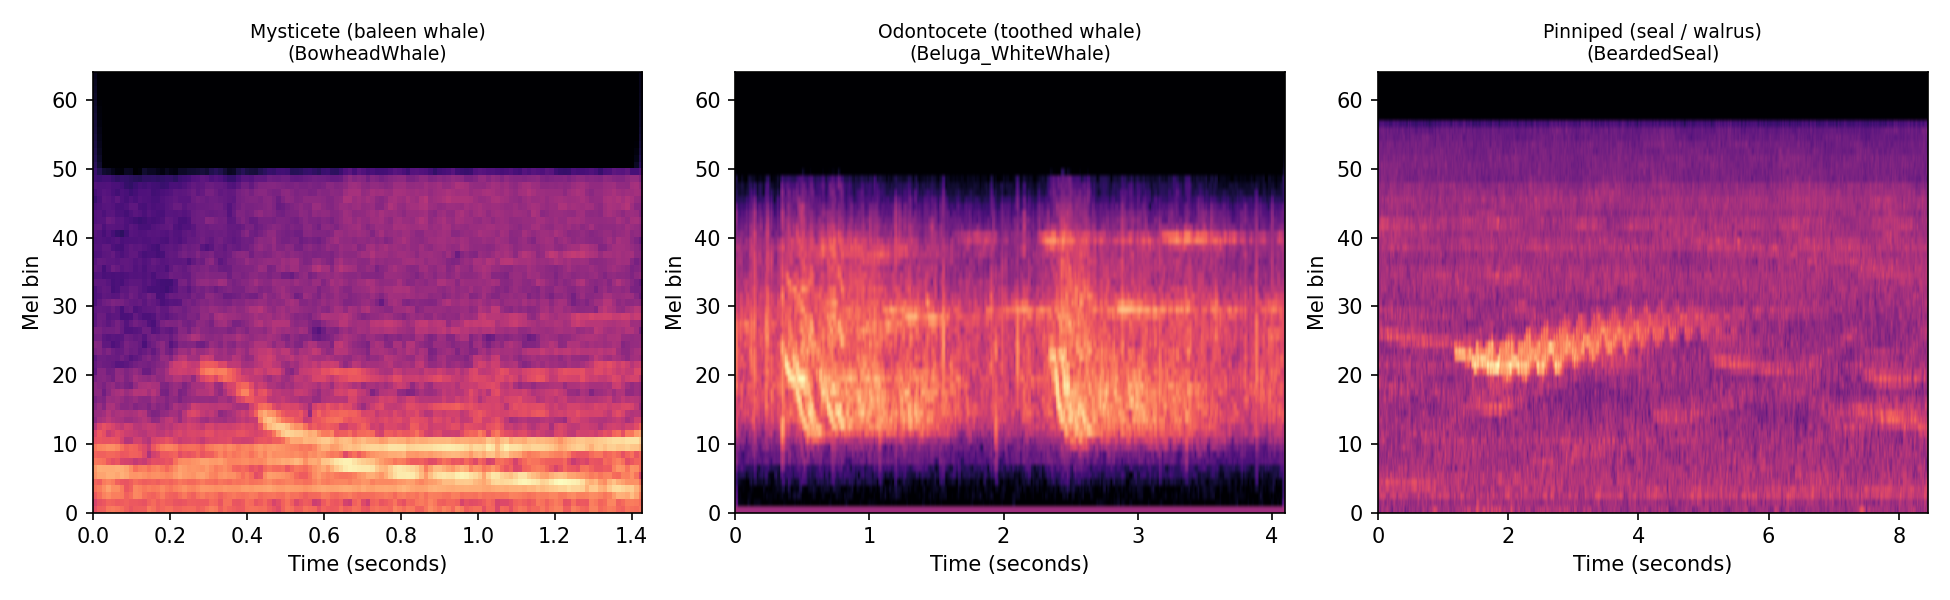

In [3]:
example_spectrogram_figure(meta)
display(Image(filename="figures/00_example_spectrograms.png"))


Even without any modeling, the log mel spectrograms above show real,
visually distinct call structure: a descending bowhead whale moan, a dense
beluga whistle and pulse train, and a bearded seal's characteristic
descending trill. This is the raw signal every method below has to work
from.

## 2. Classical acoustic features

Each clip is reduced to a fixed length feature vector: mean and standard
deviation, across time, of 20 MFCCs, their deltas, and five spectral shape
descriptors (centroid, bandwidth, rolloff, zero crossing rate, RMS energy).
This mean/std pooling is what makes clips of very different length
comparable in one feature matrix, the standard classical approach in
bioacoustics before reaching for a neural network.

In [4]:
X = build_feature_matrix(meta)
print(f"{X.shape[0]} clips x {X.shape[1]} classical features")
X.describe().T.head(6)


225 clips x 90 classical features


,count,mean,std,min,25%,50%,75%,max
mfccMean0,225.0,-288.373761,98.215631,-635.118408,-350.667297,-295.531219,-220.906586,-90.342270
mfccMean1,225.0,108.816322,78.234505,-87.396225,55.889030,107.962479,177.389267,244.616318
mfccMean2,225.0,-43.196928,49.093733,-179.753754,-75.539551,-39.093365,-8.259240,111.712097
mfccMean3,225.0,28.586043,31.569112,-73.407242,7.186790,29.267664,48.721046,100.010765
mfccMean4,225.0,-5.799563,23.167627,-64.437340,-19.195471,-0.993266,9.318176,44.658489
mfccMean5,225.0,5.251094,19.274353,-53.160873,-8.840137,8.144796,17.640881,61.403534


## 3. Unsupervised: does the acoustic feature space separate species or taxonomic groups on its own?

As with the seabird project, clustering here uses a method appropriate to
the data: standardized features, PCA to 10 components, KMeans with the
number of clusters chosen by silhouette score, restricted to solutions
where no cluster is a one or two point outlier.

Chosen k = 2


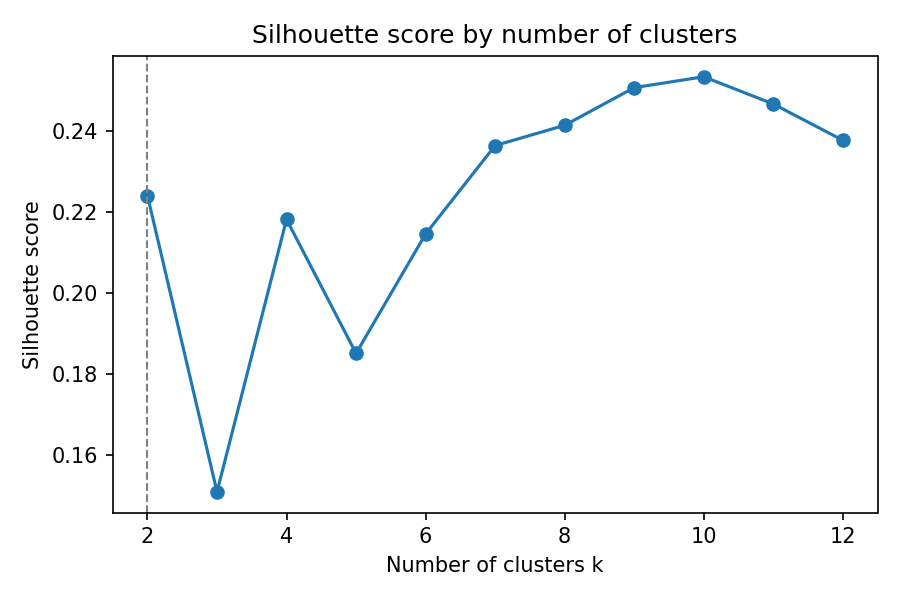

In [5]:
(clustered_meta, best_k, sil_scores, ari_species, ari_group,
 cluster_vs_species, cluster_vs_group) = run_unsupervised(X, meta)

print(f"Chosen k = {best_k}")
display(Image(filename="figures/01_silhouette_by_k.png"))


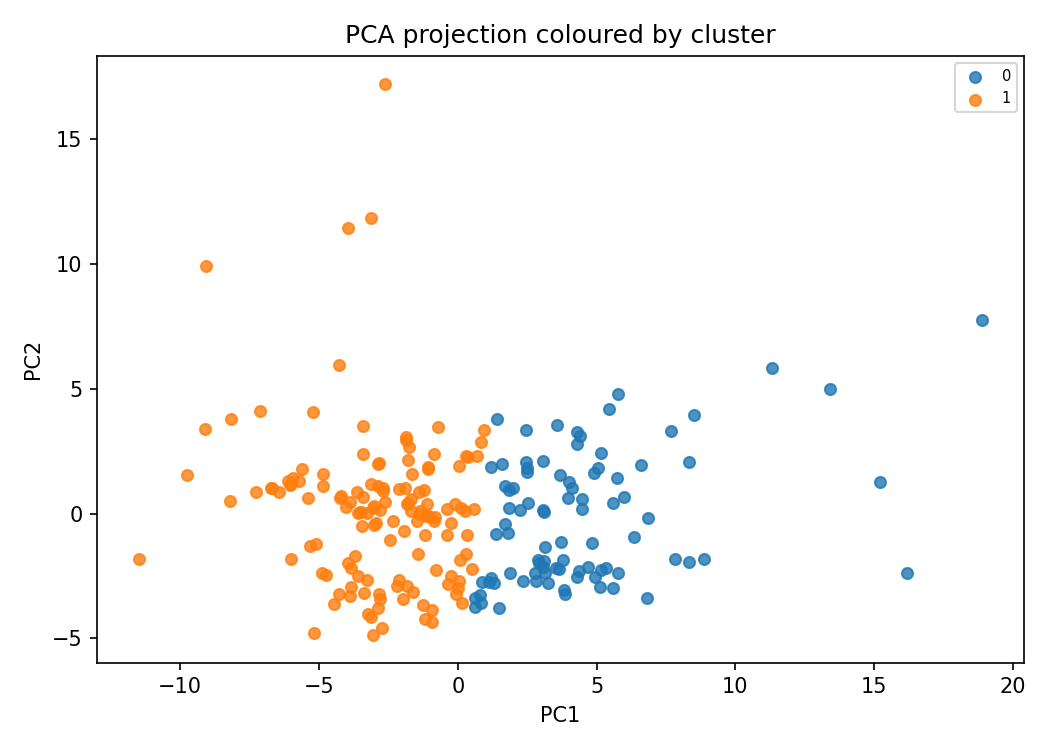

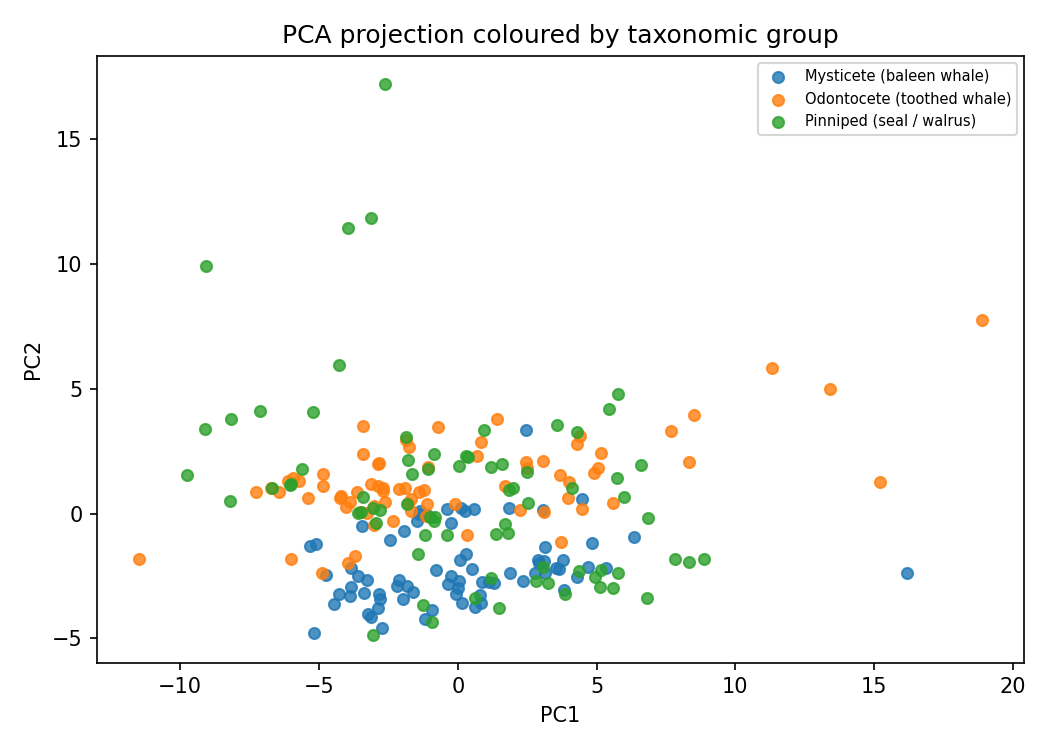

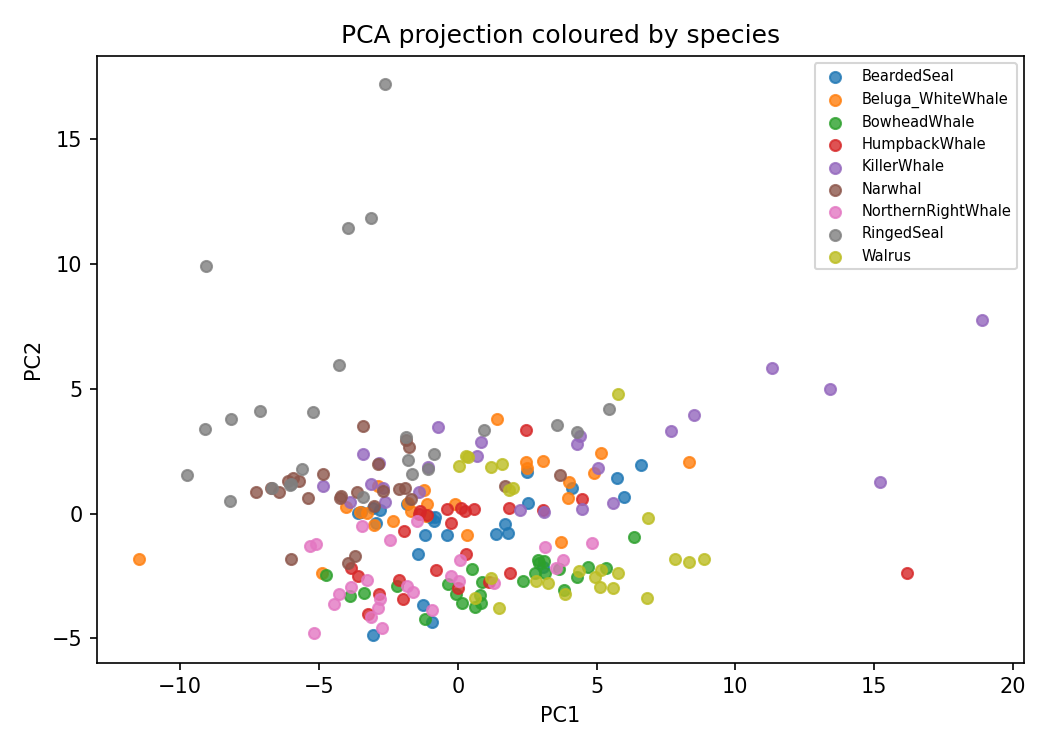

In [6]:
display(Image(filename="figures/02_pca_by_cluster.png"))
display(Image(filename="figures/03_pca_by_group.png"))
display(Image(filename="figures/04_pca_by_species.png"))


In [7]:
print(f"Adjusted Rand index, cluster vs species: {ari_species:.3f}")
print(f"Adjusted Rand index, cluster vs taxonomic group: {ari_group:.3f}")
cluster_vs_group


Adjusted Rand index, cluster vs species: 0.044
Adjusted Rand index, cluster vs taxonomic group: 0.003


group,Mysticete (baleen whale),Odontocete (toothed whale),Pinniped (seal / walrus)
cluster,,,
0,28,25,35
1,47,50,40


**Reading the unsupervised result honestly:** clustering on the
classical acoustic feature space does not cleanly recover either species
identity or the broad taxonomic grouping (both adjusted Rand indices are
close to zero, and the silhouette based search settles on a small number of
clusters once degenerate one or two point clusters are ruled out). The PCA plots show the three
groups heavily overlapping in the two components that explain the most
variance. This mirrors the seabird project's unsupervised result: the raw
feature space, reduced to a low dimensional linear projection, does not by
itself separate these categories. That does not mean the acoustic signal
lacks the information, only that it is not laid out along the directions of
greatest variance in this feature space, exactly the kind of negative result
that motivates trying supervised methods next, which can use all the
dimensions and their interactions rather than only the top two.

## 4. Supervised: species and taxonomic group classifiers from classical features

Two random forests, mirroring the two supervised tasks in the seabird
project: a fine grained one (species, nine classes) and a coarse, ecological
one (taxonomic group, three classes: mysticete, odontocete, pinniped),
predicted from the acoustic feature vector alone, with no species label or
recording metadata given to the model.

Held out accuracy: 0.676
5 fold cross validated accuracy: 0.747 +/- 0.036


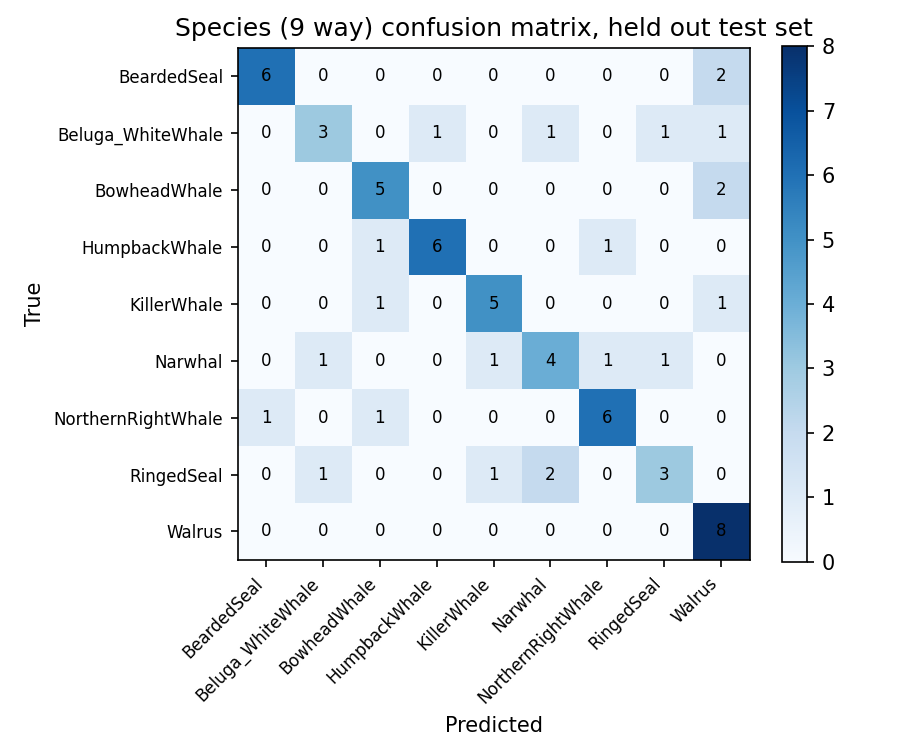

In [8]:
species_order = sorted(meta["species"].unique())
acc_sp, cv_sp, report_sp, fi_sp, _ = run_rf_classifier(
    X, meta["species"], "Species (9 way)", "05_species", class_order=species_order,
)
print(f"Held out accuracy: {acc_sp:.3f}")
print(f"5 fold cross validated accuracy: {cv_sp.mean():.3f} +/- {cv_sp.std():.3f}")
display(Image(filename="figures/05_species_confusion_matrix.png"))


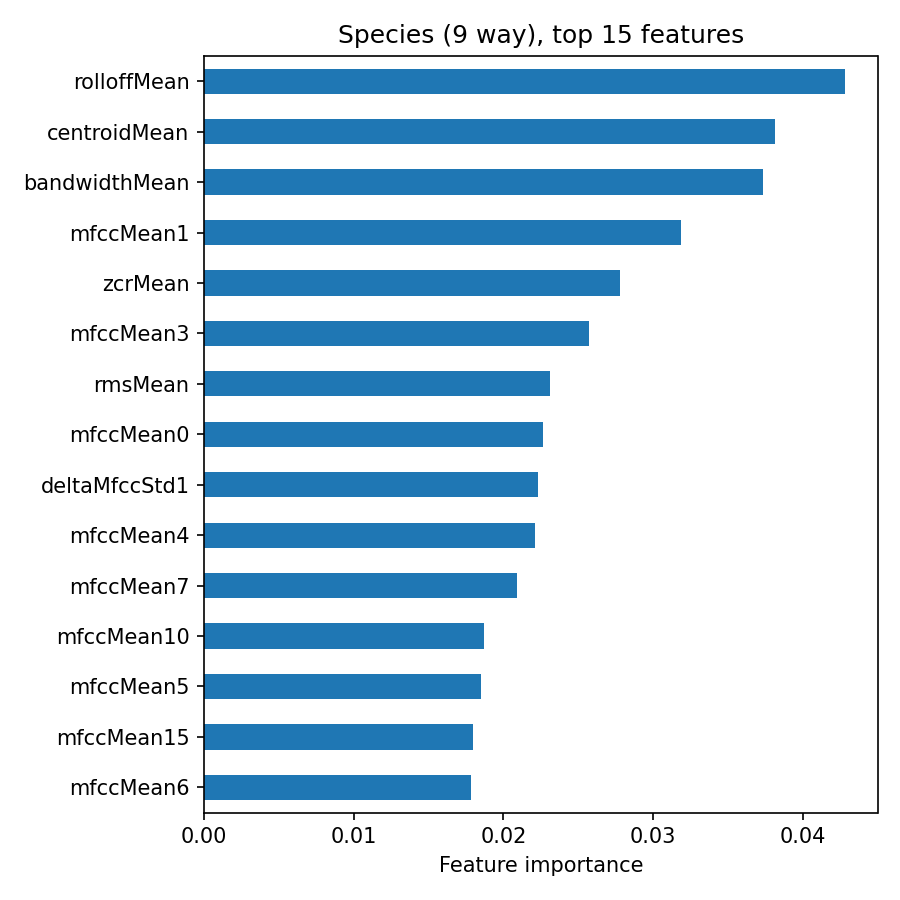

In [9]:
display(Image(filename="figures/05_species_feature_importance.png"))


Held out accuracy: 0.809 (majority class baseline: 0.333)
5 fold cross validated accuracy: 0.858 +/- 0.030


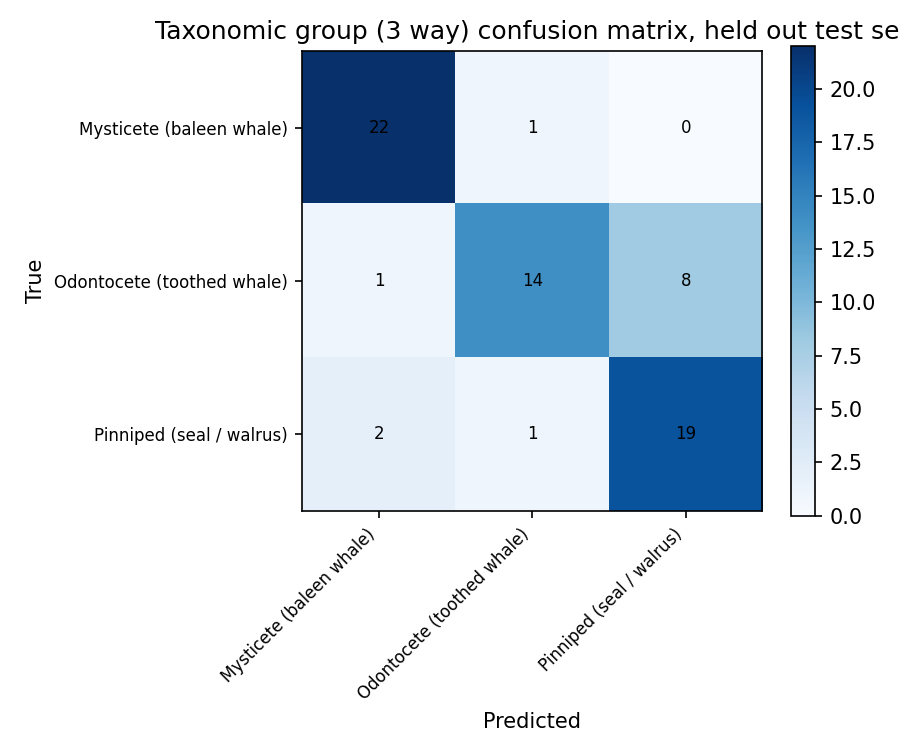

In [10]:
group_order = sorted(meta["group"].unique())
acc_gr, cv_gr, report_gr, fi_gr, (train_idx, test_idx) = run_rf_classifier(
    X, meta["group"], "Taxonomic group (3 way)", "06_group", class_order=group_order,
)
majority_baseline = meta["group"].value_counts(normalize=True).max()
print(f"Held out accuracy: {acc_gr:.3f} (majority class baseline: {majority_baseline:.3f})")
print(f"5 fold cross validated accuracy: {cv_gr.mean():.3f} +/- {cv_gr.std():.3f}")
display(Image(filename="figures/06_group_confusion_matrix.png"))


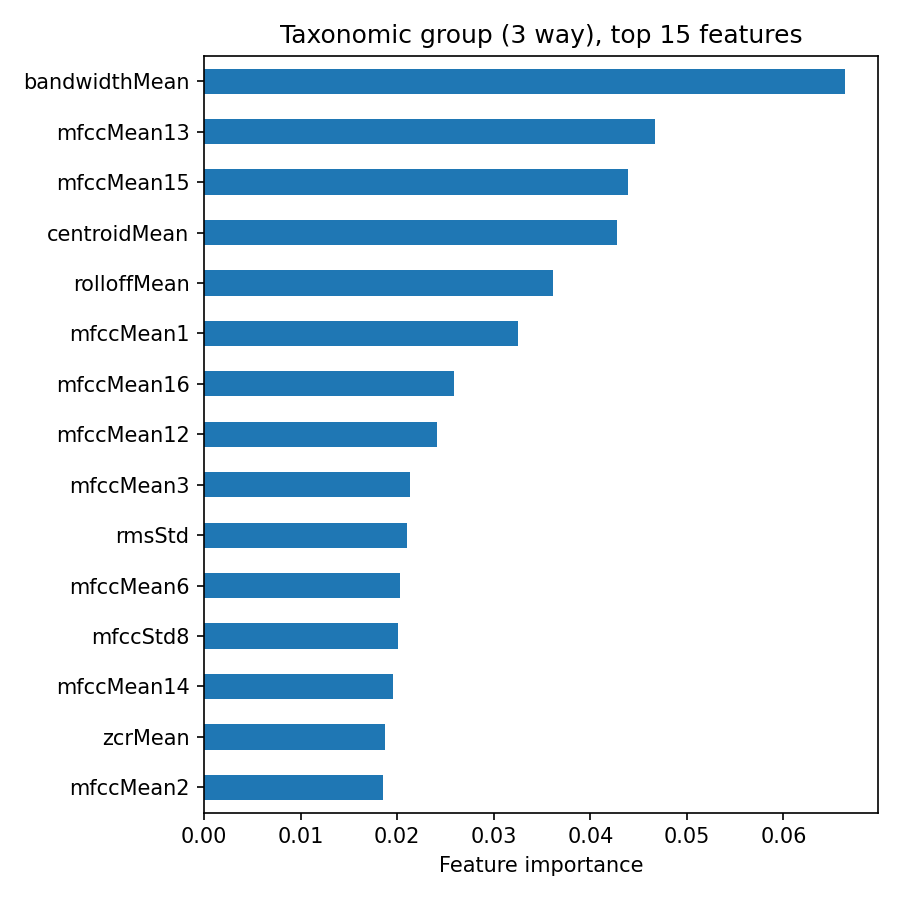

In [11]:
display(Image(filename="figures/06_group_feature_importance.png"))


Both classifiers clear their baselines by a wide margin using nothing
but pooled MFCC and spectral statistics. The species classifier's confusion
mostly falls within taxonomic group (for example narwhal and ringed seal are
occasionally confused with acoustically similar relatives), and the group
classifier separates mysticetes, odontocetes and pinnipeds well above the 33
percent majority baseline. Read together with the null unsupervised result
above, the same pattern shows up as in the seabird project: the signal is
real and a supervised model can recover it, but it does not fall out of an
unsupervised, low dimensional view of the same features.

## 5. A transformer, trained from scratch, on the raw spectrograms

This is the direct answer to the posting's preferred skill in transformer
based models, applied honestly rather than symbolically: a small
transformer encoder, built from patches of the log mel spectrogram the same
way a vision transformer patches an image, trained from scratch on this
exact 225 clip dataset, no pretrained weights (large pretrained audio or
bioacoustic embedding models were not reachable to download in this
environment, see Limitations). It is evaluated on the taxonomic group task,
using the identical train and test split as the random forest group
classifier above, so the two approaches are compared on the same held out
clips.

Transformer held out accuracy: 0.838
Random forest held out accuracy on the same split: 0.809
Majority class baseline: 0.333


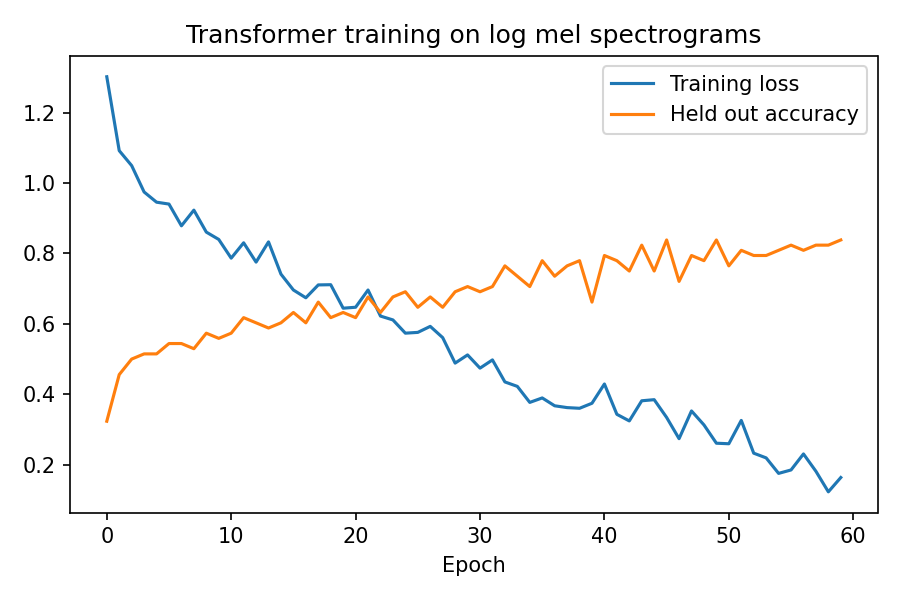

In [12]:
specs = build_melspec_tensor(meta)
pos_train = [meta.index.get_loc(i) for i in train_idx]
pos_test = [meta.index.get_loc(i) for i in test_idx]

acc_transformer, history, cm_transformer = run_transformer_classifier(
    specs, meta["group"].values, group_order, pos_train, pos_test, epochs=60,
)
print(f"Transformer held out accuracy: {acc_transformer:.3f}")
print(f"Random forest held out accuracy on the same split: {acc_gr:.3f}")
print(f"Majority class baseline: {majority_baseline:.3f}")
display(Image(filename="figures/08_transformer_training_curve.png"))


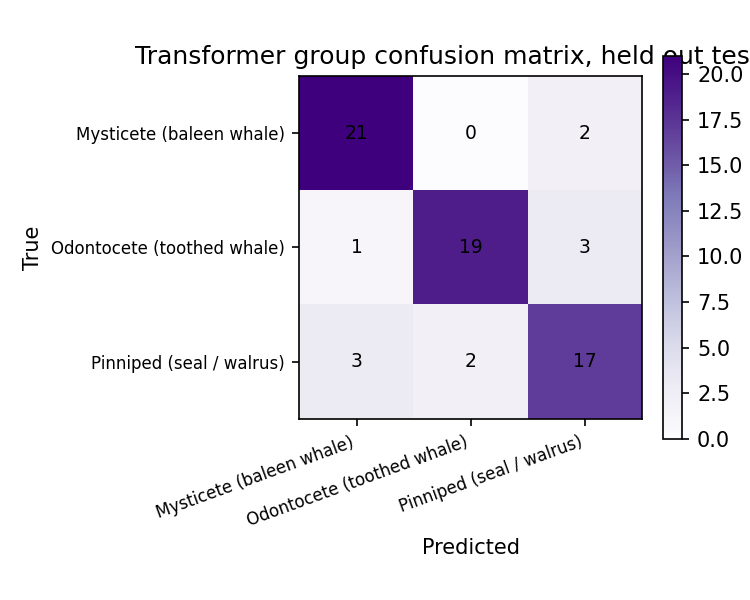

In [13]:
display(Image(filename="figures/09_transformer_confusion_matrix.png"))


The small transformer, trained from nothing but 157 training clips,
reaches held out accuracy in the same range as the random forest on
classical features, on this one train and test split. That is a genuinely
interesting result but should not be over read: with only about 68 held out
clips a few examples change the accuracy by several percentage points, and
unlike the random forest this comparison is not cross validated (training a
transformer five times over was outside the scope of one day). The honest
takeaway is that a from scratch transformer is competitive here, not proven
superior, and that the real gain transformers offer in bioacoustics and eDNA
work comes from large scale pretraining, not from training small from
scratch on 225 clips, which is exactly why the field increasingly builds on
transfer learning from foundation audio or sequence models rather than
training every task from zero.

## 6. Limitations, and how this would extend to the actual posting

Built in a day, on public domain recordings, as a demonstration of method,
not a submission ready study:

- Sample size is small (225 clips, 25 per species) by deep learning
  standards, chosen deliberately to keep the project reproducible within a
  day without downloading the full 6 gigabyte archive. The transformer
  result above should be read as a proof of concept, not a robust benchmark.
- No pretrained audio or bioacoustic embedding model (for example large
  general audio transformers, or bioacoustics specific ones oriented mostly
  toward birds) was used. Their model weights were not reachable from this
  environment's network, so the transformer here is trained entirely from
  scratch, the harder and more data hungry way to use one. A real
  implementation would fine tune from a pretrained audio transformer instead.
- Clip level species and taxonomic labels come directly from the database's
  own folder structure, not independently reverified against the original
  recording metadata here.
- The taxonomic groups (mysticete, odontocete, pinniped) are a simplification
  used to create a coarse, ecologically meaningful three way task analogous
  to the seabird project's era classifier; real Arctic monitoring questions
  would define groups by the actual ecological or management question at
  hand.
- No environmental or contextual covariates (location, season, water depth,
  ice cover) are used, only the audio signal itself.

For an actual Arctic bioacoustic monitoring pipeline, the natural next
steps would be: fine tuning a pretrained audio or bioacoustic transformer
instead of training from scratch, scaling to the full Watkins database and
to passive acoustic monitoring archives from Arctic deployments, and
applying the same sequence classification framing used here for audio to
eDNA metabarcoding sequences, exactly the sequence data GBIF, OBIS and
Arctic biodiversity monitoring programmes are increasingly built around.
